In [256]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [257]:
url = "https://raw.githubusercontent.com/Sainathmudigonda/Student-Result-Analysis/main/student_exam_scores.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (200, 6)


,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3


In [258]:



print("DATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nSTATISTICAL SUMMARY")
display(df.describe())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          200 non-null    object 
 1   hours_studied       200 non-null    float64
 2   sleep_hours         200 non-null    float64
 3   attendance_percent  200 non-null    float64
 4   previous_scores     200 non-null    int64  
 5   exam_score          200 non-null    float64
dtypes: float64(4), int64(1), object(1)
memory usage: 9.5+ KB

MISSING VALUES
student_id            0
hours_studied         0
sleep_hours           0
attendance_percent    0
previous_scores       0
exam_score            0
dtype: int64

DUPLICATE ROWS
0

STATISTICAL SUMMARY


,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,6.325500,6.622000,74.830000,66.800000,33.955000
std,3.227317,1.497138,14.249905,15.663869,6.789548
min,1.000000,4.000000,50.300000,40.000000,17.100000
25%,3.500000,5.300000,62.200000,54.000000,29.500000
50%,6.150000,6.700000,75.250000,67.500000,34.050000
75%,9.000000,8.025000,87.425000,80.000000,38.750000
max,12.000000,9.000000,100.000000,95.000000,51.300000


In [259]:
print("Duplicate Student IDs:")
print(df["student_id"].duplicated().sum())

print("\nMinimum and Maximum Values:")
print(df[["hours_studied", "sleep_hours",
          "attendance_percent", "previous_scores",
          "exam_score"]].agg(["min", "max"]))

print("\nData validation completed!")


Duplicate Student IDs:
0

Minimum and Maximum Values:
     hours_studied  sleep_hours  attendance_percent  previous_scores  \
min            1.0          4.0                50.3               40   
max           12.0          9.0               100.0               95   

     exam_score  
min        17.1  
max        51.3  

Data validation completed!


In [260]:
# Select numerical columns
numerical_data = df.select_dtypes(include="number").drop(
    columns=["student_id"], errors="ignore"
)

# Calculate statistical measures
statistics = pd.DataFrame({
    "Mean": numerical_data.mean(),
    "Median": numerical_data.median(),
    "Mode": numerical_data.mode().iloc[0],
    "Standard Deviation": numerical_data.std(),
    "Variance": numerical_data.var(),
    "Minimum": numerical_data.min(),
    "Maximum": numerical_data.max()
})

print("DESCRIPTIVE STATISTICAL ANALYSIS")
display(statistics.round(2))

DESCRIPTIVE STATISTICAL ANALYSIS


,Mean,Median,Mode,Standard Deviation,Variance,Minimum,Maximum
hours_studied,6.33,6.15,3.9,3.23,10.42,1.0,12.0
sleep_hours,6.62,6.70,5.5,1.50,2.24,4.0,9.0
attendance_percent,74.83,75.25,92.5,14.25,203.06,50.3,100.0
previous_scores,66.80,67.50,58.0,15.66,245.36,40.0,95.0
exam_score,33.96,34.05,36.1,6.79,46.10,17.1,51.3


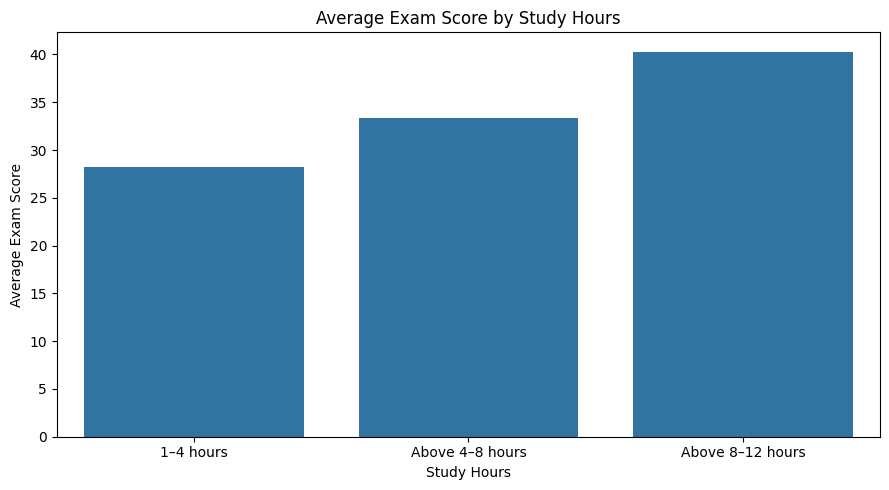

In [261]:
import matplotlib.pyplot as plt
import seaborn as sns

# Divide students into study-hour groups
df["study_group"] = pd.cut(
    df["hours_studied"],
    bins=[0, 4, 8, 12],
    labels=["1–4 hours", "Above 4–8 hours", "Above 8–12 hours"],
    include_lowest=True
)

# Calculate average exam score for each group
average_scores = df.groupby(
    "study_group", observed=False
)["exam_score"].mean().reset_index()

# Create bar chart
plt.figure(figsize=(9, 5))

sns.barplot(
    data=average_scores,
    x="study_group",
    y="exam_score"
)

plt.title("Average Exam Score by Study Hours")
plt.xlabel("Study Hours")
plt.ylabel("Average Exam Score")
plt.tight_layout()
plt.show()


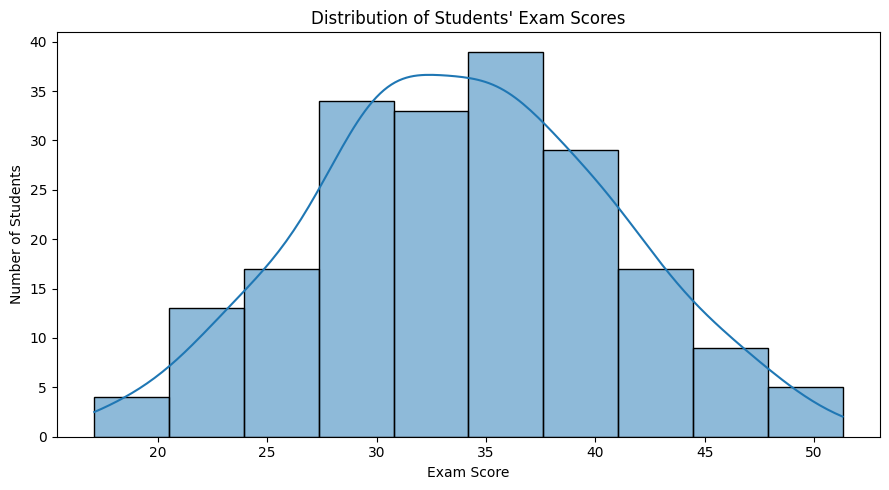

In [262]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="exam_score",
    bins=10,
    kde=True
)

plt.title("Distribution of Students' Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()


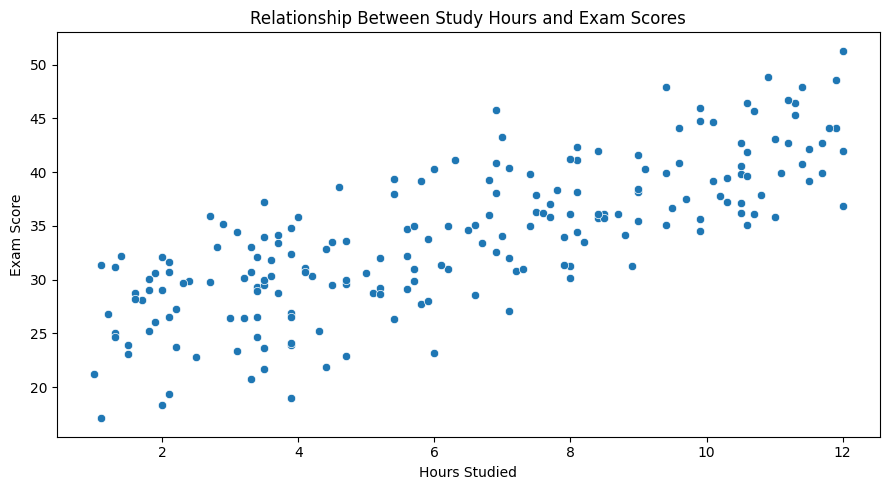

In [263]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="hours_studied",
    y="exam_score"
)

plt.title("Relationship Between Study Hours and Exam Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")

plt.tight_layout()
plt.show()


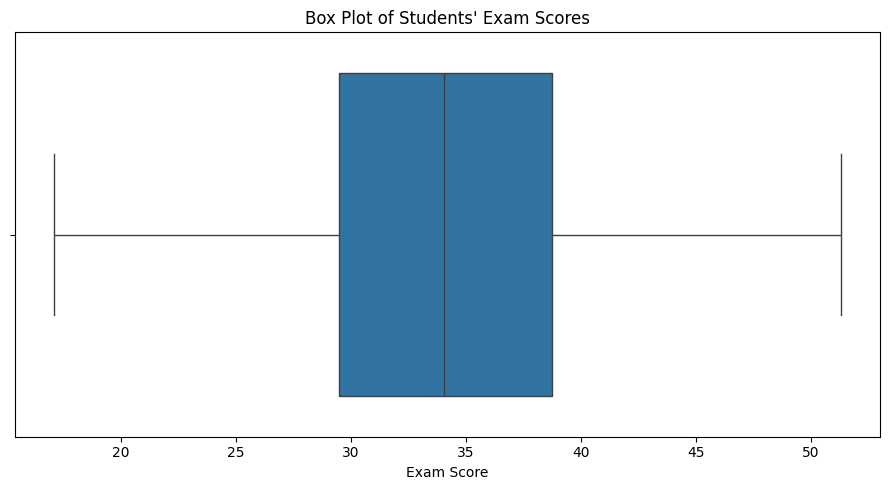

In [264]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    x=df["exam_score"]
)

plt.title("Box Plot of Students' Exam Scores")
plt.xlabel("Exam Score")

plt.tight_layout()
plt.show()


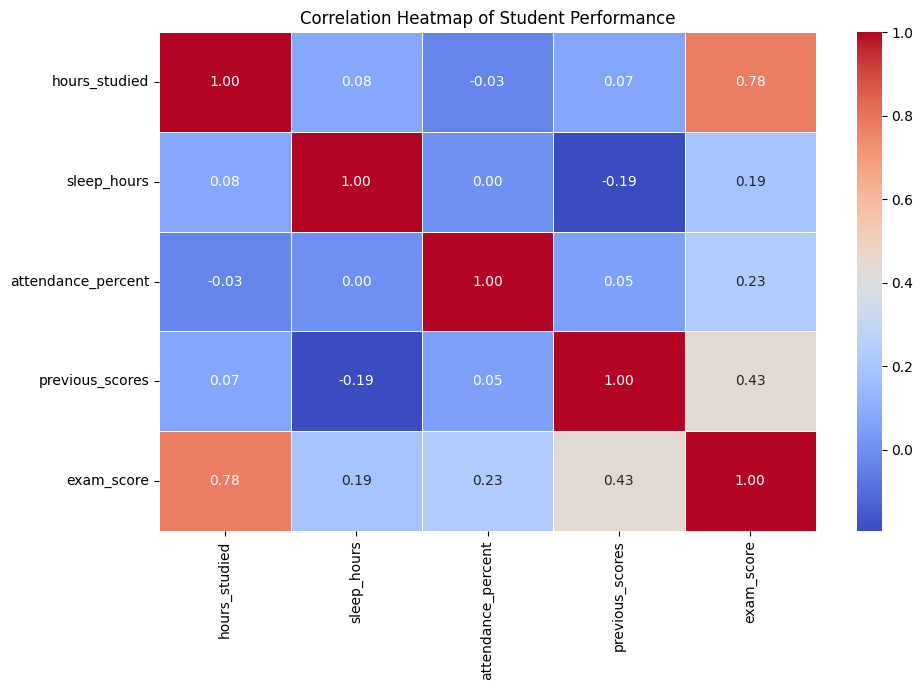

In [265]:
# Select numerical columns
correlation_data = df.select_dtypes(include="number")

# Calculate correlation
correlation_matrix = correlation_data.corr()

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Student Performance")
plt.tight_layout()
plt.show()

In [266]:
X = df[[
    "hours_studied",
    "sleep_hours",
    "attendance_percent",
    "previous_scores"
]]

y = df["exam_score"]

print("Input variables (X):")
display(X.head())

print("Output variable (y):")
display(y.head())

print("Input shape:", X.shape)
print("Output shape:", y.shape)


Input variables (X):


,hours_studied,sleep_hours,attendance_percent,previous_scores
0,8.0,8.8,72.1,45
1,1.3,8.6,60.7,55
2,4.0,8.2,73.7,86
3,3.5,4.8,95.1,66
4,9.1,6.4,89.8,71


Output variable (y):


,exam_score
0,30.2
1,25.0
2,35.8
3,34.0
4,40.3


Input shape: (200, 4)
Output shape: (200,)


In [267]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training and Testing Data Split Successfully!")

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


Training and Testing Data Split Successfully!
X_train shape: (160, 4)
X_test shape: (40, 4)
y_train shape: (160,)
y_test shape: (40,)


In [268]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)

print("Linear Regression Model trained successfully!")

print("Model Intercept:", model.intercept_)

print("\nModel Coefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", round(coefficient, 4))


Linear Regression Model trained successfully!
Model Intercept: -2.204963905836877

Model Coefficients:
hours_studied : 1.5493
sleep_hours : 0.8842
attendance_percent : 0.1089
previous_scores : 0.183


In [269]:
# Predict scores using testing data
y_pred = model.predict(X_test)

# Compare actual and predicted scores
results = pd.DataFrame({
    "Actual Exam Score": y_test.values,
    "Predicted Exam Score": y_pred.round(2)
})

print("ACTUAL VS PREDICTED EXAM SCORES")

display(results.head(10))


ACTUAL VS PREDICTED EXAM SCORES


,Actual Exam Score,Predicted Exam Score
0,28.7,28.89
1,34.1,29.68
2,34.5,35.31
3,29.5,31.18
4,36.1,39.45
5,46.4,41.69
6,23.9,23.97
7,45.3,45.72
8,44.8,41.65
9,31.8,27.48


In [270]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))


MODEL EVALUATION RESULTS
MAE: 2.31
RMSE: 2.79
R2 Score: 0.8537


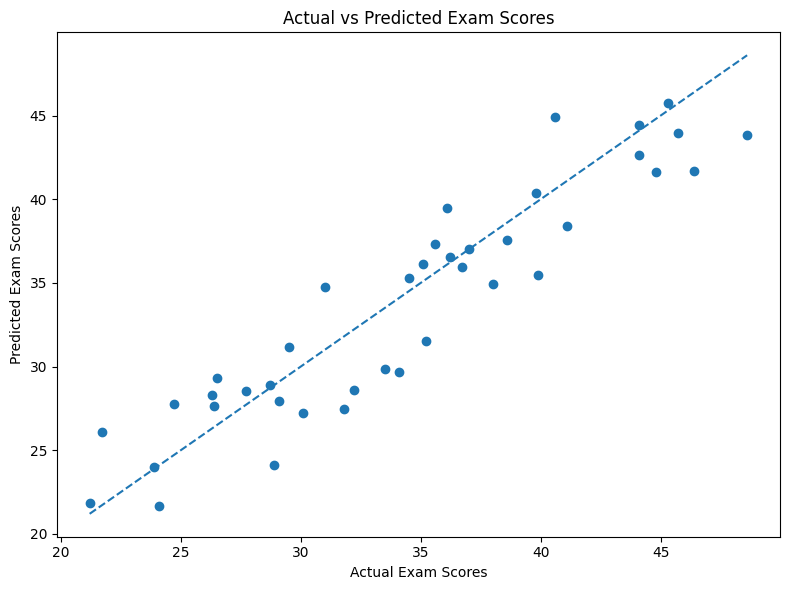

In [271]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

# Reference line for perfect predictions
min_score = min(y_test.min(), y_pred.min())
max_score = max(y_test.max(), y_pred.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    linestyle="--"
)

plt.title("Actual vs Predicted Exam Scores")
plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")

plt.tight_layout()
plt.show()


In [272]:
evaluation_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Value": [mae, rmse, r2]
})

evaluation_results.to_csv(
    "model_evaluation_results.csv",
    index=False
)

results.to_csv(
    "actual_vs_predicted.csv",
    index=False
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [273]:
import joblib

joblib.dump(model, "student_performance_model.pkl")

print("Trained model saved successfully!")


Trained model saved successfully!


In [274]:
df.to_csv("student_performance_dataset.csv", index=False)

print("Dataset saved successfully!")


Dataset saved successfully!


In [275]:
import os

print("Available project files:")

for file in os.listdir():
    if file.endswith((".csv", ".pkl")):
        print(file)


Available project files:
student_performance_model.pkl
model_evaluation_results.csv
actual_vs_predicted.csv
student_performance_dataset.csv


In [276]:
import zipfile

project_files = [
    "student_performance_dataset.csv",
    "model_evaluation_results.csv",
    "actual_vs_predicted.csv",
    "student_performance_model.pkl"
]

with zipfile.ZipFile(
    "Student_Performance_Project_Files.zip", "w"
) as zip_file:

    for file in project_files:
        zip_file.write(file)

print("Project ZIP folder created successfully!")

from google.colab import files
files.download("Student_Performance_Project_Files.zip")


Project ZIP folder created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [277]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("project_graphs", exist_ok=True)

# 1. Bar Chart
plt.figure(figsize=(9, 5))
sns.barplot(data=average_scores, x="study_group", y="exam_score")
plt.title("Average Exam Score by Study Hours")
plt.xlabel("Study Hours")
plt.ylabel("Average Exam Score")
plt.tight_layout()
plt.savefig("project_graphs/1_bar_chart.png", dpi=300)
plt.close()

# 2. Histogram
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="exam_score", bins=10, kde=True)
plt.title("Distribution of Students' Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.savefig("project_graphs/2_histogram.png", dpi=300)
plt.close()

# 3. Scatter Plot
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="hours_studied", y="exam_score")
plt.title("Study Hours vs Exam Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.tight_layout()
plt.savefig("project_graphs/3_scatter_plot.png", dpi=300)
plt.close()

# 4. Box Plot
plt.figure(figsize=(9, 5))
sns.boxplot(x=df["exam_score"])
plt.title("Box Plot of Students' Exam Scores")
plt.xlabel("Exam Score")
plt.tight_layout()
plt.savefig("project_graphs/4_box_plot.png", dpi=300)
plt.close()

# 5. Correlation Heatmap
correlation_data = df.select_dtypes(include="number").drop(
    columns=["student_id"], errors="ignore"
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Student Performance")
plt.tight_layout()
plt.savefig("project_graphs/5_correlation_heatmap.png", dpi=300)
plt.close()

print("All 5 graphs saved successfully!")


All 5 graphs saved successfully!


In [278]:
import shutil
from google.colab import files

shutil.make_archive(
    "Student_Performance_Graphs",
    "zip",
    "project_graphs"
)

files.download("Student_Performance_Graphs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>